In [43]:
import numpy as np
import matplotlib.pyplot as plt

In [44]:
def cubic_spline(x, y, xp):
  n = len(x) - 1
  A = np.zeros((4 * n, 4 * n))
  b = np.zeros(4 * n)
  row = 0
  equations = []
  # Setting up equations for spline segments
  for i in range(n):
    A[row, 4*i] = x[i]**3
    A[row, 4*i + 1] = x[i]**2
    A[row, 4*i + 2] = x[i]
    A[row, 4*i + 3] = 1
    b[row] = y[i]
    row += 1
    A[row, 4*i] = x[i+1]**3
    A[row, 4*i + 1] = x[i+1]**2
    A[row, 4*i + 2] = x[i+1]
    A[row, 4*i + 3] = 1
    b[row] = y[i+1]
    row += 1
  # First derivative continuity
  for i in range(n-1):
    A[row, 4*i] = 3 * x[i+1]**2
    A[row, 4*i + 1] = 2 * x[i+1]
    A[row, 4*i + 2] = 1
    A[row, 4*i + 4] = -3 * x[i+1]**2
    A[row, 4*i + 5] = -2 * x[i+1]
    A[row, 4*i + 6] = -1
    row += 1
  # Second derivative continuity
  for i in range(n-1):
    A[row, 4*i] = 6 * x[i+1]
    A[row, 4*i + 1] = 2
    A[row, 4*i + 4] = -6 * x[i+1]
    A[row, 4*i + 5] = -2
    row += 1
  # Natural spline conditions (second derivate at endpoints = 0)
  A[row, 0] = 6 * x[0]
  A[row, 1] = 2
  row += 1
  A[row, -4] = 6 * x[-1]
  A[row, -3] = 2
  coeffs = np.linalg.solve(A, b)
  # Constructing spline equations
  for i in range(n):
    a, b, c, d = coeffs[4*i : 4*i+4]
    eq = f"S_{i}(x) = {a:.4f}x^3 + {b:.4f}x^2 + {c:.4f}x + {d:.4f}, for {x[i]} <= x <= {x[i+1]}"
    equations.append(eq)
    print(eq)
  # Finding interpolated value
  y_interp = None
  for i in range(n):
    if x[i] <= xp <= x[i+1]:
      y_interp = coeffs[4*i]*xp**3 + coeffs[4*i + 1]*xp**2 + coeffs[4*i + 2]*xp + coeffs[4*i + 3]
      break
  return equations, y_interp, coeffs

In [45]:
# Example Data Points
x_points = np.array([0, 1, 2, 3, 4, 5, 6])
y_points = np.array([1, 2, 0, 2, 3, 5, 8])
# x_points = np.array([0, 1, 2, 3])
# y_points = np.array([1, 2, 33, 244])

In [46]:
# Interpolation Points
x_interp = 2.5
splines, y_interp, coeffs = cubic_spline(x_points, y_points, x_interp)
print(f'Interpolated value at x = {x_interp}: {y_interp:.4f}')

S_0(x) = -1.1141x^3 + 0.0000x^2 + 2.1141x + 1.0000, for 0 <= x <= 1
S_1(x) = 2.5705x^3 + -11.0538x^2 + 13.1679x + -2.6846, for 1 <= x <= 2
S_2(x) = -2.1679x^3 + 17.3769x^2 + -43.6936x + 35.2231, for 2 <= x <= 3
S_3(x) = 1.1013x^3 + -12.0462x^2 + 44.5756x + -53.0462, for 3 <= x <= 4
S_4(x) = -0.2372x^3 + 4.0154x^2 + -19.6705x + 32.6154, for 4 <= x <= 5
S_5(x) = -0.1526x^3 + 2.7462x^2 + -13.3244x + 22.0385, for 5 <= x <= 6
Interpolated value at x = 2.5: 0.7207


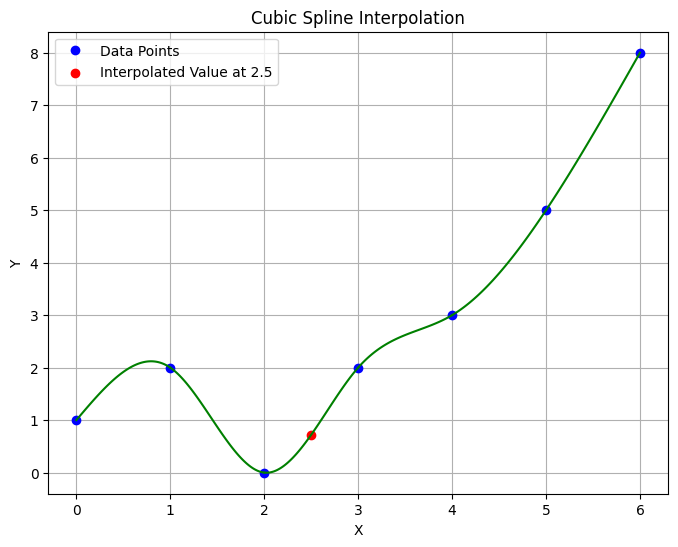

In [47]:
# Plotting
plt.figure(figsize=(8, 6))
plt.plot(x_points, y_points, 'bo', label='Data Points')
plt.scatter(x_interp, y_interp, color='red', label=f'Interpolated Value at {x_interp}')
# Plot quadratic spline segments
for i in range(len(x_points)-1):
  x_vals = np.linspace(x_points[i], x_points[i+1], 100)
  y_vals = (coeffs[4*i]*x_vals**3 + coeffs[4*i + 1]*x_vals**2 + coeffs[4*i + 2]*x_vals + coeffs[4*i + 3])
  plt.plot(x_vals, y_vals, 'g-')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Cubic Spline Interpolation')
plt.legend()
plt.grid(True)
plt.show()